In [1]:
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score


In [2]:
insurance_df=pd.read_csv("./dataset/insurance.csv")
x=insurance_df.drop(columns=["charges"])
y=insurance_df["charges"]
x=pd.get_dummies(x,columns=["region"],drop_first=True,dtype=int)

x["sex"]=x["sex"].map({"female":1,"male":0})
x["smoker"]=x["smoker"].map({"yes":1,"no":0})

x["age_smoker"]=x["age"]*x["smoker"]
x["bmi_smoker"]=x["bmi"]*x["smoker"]

x_train, x_test, y_train, y_test= train_test_split(
    x,y,test_size=0.2, random_state=42
)


MSE for alpha=0.001:  20922599.871035974
MSE for alpha=0.1:  20921803.698431384
MSE for alpha=1:  20914832.635089148
MSE for alpha=2:  20908106.779954527
MSE for alpha=5:  20890881.000633508
MSE for alpha=10:  20872844.79479669
MSE for alpha=20:  20877828.53237883
MSE for alpha=30:  20937537.133939765
MSE for alpha=40:  21046489.293890767
MSE for alpha=50:  21196929.869608894
MSE for alpha=100:  22423172.686023224


<Axes: >

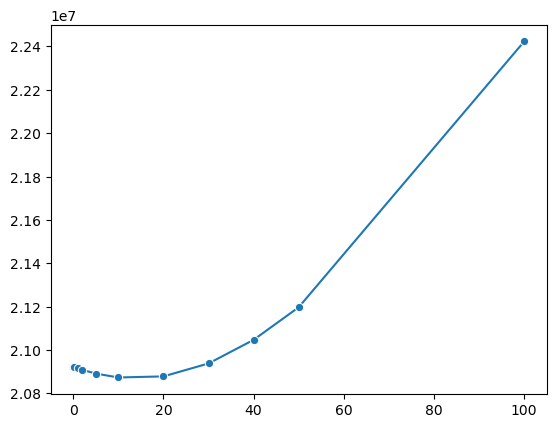

In [10]:
import seaborn as sns

alphas=[0.001,0.1,1,2,5,10,20,30,40,50,100]
mses=[]
y_pred=None
for a in alphas:
    lasso_model=Lasso(alpha=a)
    lasso_model.fit(x_train,y_train)
    y_pred=lasso_model.predict(x_test)
    mse=mean_squared_error(y_test,y_pred)
    print(f"MSE for alpha={a}: ", mse)
    mses.append(mse)

sns.lineplot(x=alphas,y=mses, marker="o")
    

In [5]:
# evaluation metrics

cm=confusion_matrix(y_test, y_pred)
print(cm)
print("accuracy score: ", accuracy_score(y_test, y_pred))
print("precision score: ", precision_score(y_test, y_pred))
print("recall score: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))

ValueError: continuous is not supported

In [21]:
a=alphas
a.append(0.0001)

In [24]:
lasso_cv_model=LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state=42
)
lasso_cv_model.fit(x_train,y_train)
print("best alpha:" , lasso_cv_model.alpha_)

y_pred = lasso_cv_model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("mse = ", mse)
print("s2 = ", r2)

best alpha: 0.0001
mse =  20922607.131011534
s2 =  0.8652317031516601
